
     CUKKOO SEARCH OPTIMIZATION RESULTS
Optimization Status: Completed Successfully!
Total Iterations executed: 150
Optimal Path Metric Score (Fitness): 17.3131

OPTIMIZED WAYPOINT COORDINATES
----------------------------------------------
Start Point -> [0. 0.]
Waypoint 1 -> [0.00, 0.00]
Waypoint 2 -> [0.00, 1.13]
Waypoint 3 -> [0.00, 2.92]
Waypoint 4 -> [1.12, 6.96]
Waypoint 5 -> [3.95, 10.00]
Goal Node   -> [10. 10.]


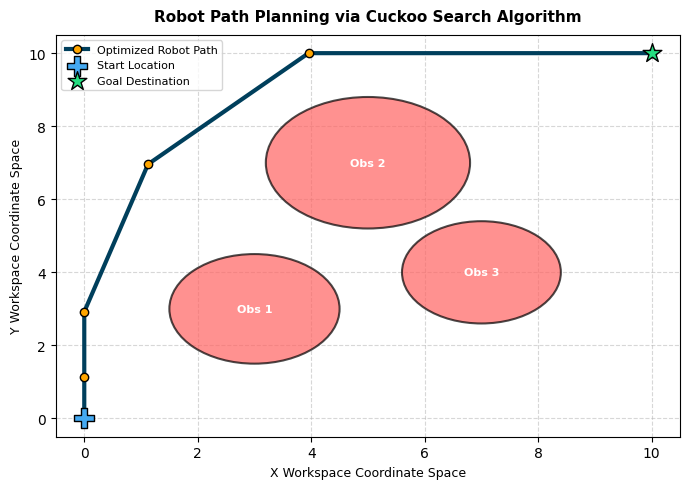

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.special as special

# =====================================================
# CUKKOO SEARCH (CS) ALGORITHM FOR ROBOT PATH PLANNING
# =====================================================
np.random.seed(42)

# STEP 1: Define the Problem (Environment & Objectives)
start_node = np.array([0.0, 0.0])
goal_node = np.array([10.0, 10.0])

# Circular obstacles defined as (x, y, radius)
obstacles = [
    (3.0, 3.0, 1.5),
    (5.0, 7.0, 1.8),
    (7.0, 4.0, 1.4)
]

num_waypoints = 5  # Number of internal nodes in the path
dim = num_waypoints * 2  # Each waypoint has x and y coordinates
lower_bound = 0.0
upper_bound = 10.0

def calculate_fitness(path_vector):
    """Evaluates the path length and adds a severe penalty for obstacle collisions."""
    points = path_vector.reshape((num_waypoints, 2))
    full_path = np.vstack([start_node, points, goal_node])

    total_length = 0.0
    obstacle_penalty = 0.0

    # Calculate path length and check segment collisions
    for i in range(len(full_path) - 1):
        p1 = full_path[i]
        p2 = full_path[i+1]

        # Euclidean distance of the segment
        segment_dist = np.linalg.norm(p2 - p1)
        total_length += segment_dist

        # Check collision along the path segment using localized sampling
        samples = np.linspace(0, 1, 20)
        for t in samples:
            check_point = p1 + t * (p2 - p1)
            for ox, oy, r in obstacles:
                dist_to_obstacle = np.linalg.norm(check_point - np.array([ox, oy]))
                if dist_to_obstacle <= r:
                    # Penalty proportional to how deep inside the obstacle the path goes
                    obstacle_penalty += 1000.0 * (r - dist_to_obstacle + 0.1)

    return total_length + obstacle_penalty

# STEP 2: Initialize CS Parameters
num_nests = 25
max_iter = 150
pa = 0.25         # Discovery probability of alien eggs
alpha = 0.1       # Step size scaling factor
levy_beta = 1.5   # Lévy flight exponent

# STEP 3: Initialize Population (Random Initial Nests/Paths)
nests = np.random.uniform(lower_bound, upper_bound, (num_nests, dim))
fitness = np.array([calculate_fitness(n) for n in nests])

# Track global best discovery
best_idx = np.argmin(fitness)
best_nest = nests[best_idx].copy()
best_fitness = fitness[best_idx]

# Precompute standard deviation for standard Lévy distribution calculation
sigma_u = (special.gamma(1 + levy_beta) * np.sin(np.pi * levy_beta / 2) /
           (special.gamma((1 + levy_beta) / 2) * levy_beta * 2**((levy_beta - 1) / 2)))**(1 / levy_beta)

def levy_flight(current_position, global_best, step_size_alpha):
    """Generates a random walk step drawn from a heavy-tailed Lévy distribution."""
    u = np.random.normal(0, sigma_u, size=dim)
    v = np.random.normal(0, 1, size=dim)
    step = u / (np.abs(v)**(1 / levy_beta))

    # Step direction relies on difference from current best nest
    step_direction = current_position - global_best
    new_position = current_position + step_size_alpha * step * step_direction
    return np.clip(new_position, lower_bound, upper_bound)

# =====================================================
# STEP 7: CUKKOO SEARCH MAIN ITERATIVE PROCESS
# =====================================================
for iteration in range(max_iter):

    # --- PHASE A: Generate New Solutions via Lévy Flights ---
    i = np.random.randint(0, num_nests)
    new_nest = levy_flight(nests[i], best_nest, alpha)
    new_fit = calculate_fitness(new_nest)

    # Replace randomly chosen nest if the new cuckoo path offers better fitness
    j = np.random.randint(0, num_nests)
    if new_fit < fitness[j]:
        nests[j] = new_nest
        fitness[j] = new_fit

    # --- PHASE B: Abandon a Fraction (pa) of Worst Nests ---
    abandon_mask = np.random.rand(num_nests) < pa

    # Biased random walk replacement based on population variety
    random_per1 = np.random.permutation(num_nests)
    random_per2 = np.random.permutation(num_nests)

    step_size = np.random.rand(num_nests, dim) * (nests[random_per1] - nests[random_per2])

    # FIXED LINE: Using [:, np.newaxis] ensures correct 2D dimension broadcasting
    nests_discovered = nests + step_size * abandon_mask[:, np.newaxis]
    nests = np.clip(nests_discovered, lower_bound, upper_bound)

    # Re-evaluate entire nest population fitness profiles
    fitness = np.array([calculate_fitness(n) for n in nests])

    # Update current best solution found globally
    current_best_idx = np.argmin(fitness)
    if fitness[current_best_idx] < best_fitness:
        best_fitness = fitness[current_best_idx]
        best_nest = nests[current_best_idx].copy()

# =====================================================
# STEP 8: OUTPUT BEST SOLUTION & METRICS
# =====================================================
print("\n==============================================")
print("     CUKKOO SEARCH OPTIMIZATION RESULTS")
print("==============================================")
print(f"Optimization Status: Completed Successfully!")
print(f"Total Iterations executed: {max_iter}")
print(f"Optimal Path Metric Score (Fitness): {best_fitness:.4f}")

# Reconstruct best waypoint configurations
best_waypoints = best_nest.reshape((num_waypoints, 2))
optimized_full_path = np.vstack([start_node, best_waypoints, goal_node])

print("\nOPTIMIZED WAYPOINT COORDINATES")
print("----------------------------------------------")
print(f"Start Point -> {start_node}")
for idx, wp in enumerate(best_waypoints):
    print(f"Waypoint {idx + 1} -> [{wp[0]:.2f}, {wp[1]:.2f}]")
print(f"Goal Node   -> {goal_node}")

# =====================================================
# STEP 16: ROBOT PATH PLANNING NETWORK DIAGRAM (MEDIUM)
# =====================================================
fig, ax1 = plt.subplots(figsize=(7, 5))

# Plot circular obstacles in workspace environment
for index, (ox, oy, r) in enumerate(obstacles):
    obstacle_circle = plt.Circle((ox, oy), r, color="#ff6361", alpha=0.7, ec="black", lw=1.5, zorder=2)
    ax1.add_patch(obstacle_circle)
    ax1.text(ox, oy, f"Obs {index+1}", color="white", weight="bold", ha="center", va="center", fontsize=8, zorder=3)

# Plot generated optimized path configuration lines
ax1.plot(optimized_full_path[:, 0], optimized_full_path[:, 1], color="#003f5c", lw=3, linestyle="-", marker="o",
         markersize=6, mfc="#ffa600", mec="black", label="Optimized Robot Path", zorder=4)

# Highlight unique endpoint positions
ax1.scatter(start_node[0], start_node[1], color="#45aaf2", edgecolors="black", s=200, marker="P", label="Start Location", zorder=5)
ax1.scatter(goal_node[0], goal_node[1], color="#26de81", edgecolors="black", s=200, marker="*", label="Goal Destination", zorder=5)

# Graphical polish adjustments
ax1.set_title("Robot Path Planning via Cuckoo Search Algorithm", fontsize=11, fontweight="bold", pad=10)
ax1.set_xlabel("X Workspace Coordinate Space", fontsize=9)
ax1.set_ylabel("Y Workspace Coordinate Space", fontsize=9)
ax1.set_xlim(lower_bound - 0.5, upper_bound + 0.5)
ax1.set_ylim(lower_bound - 0.5, upper_bound + 0.5)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()
